# Power Transform

In [1]:
import pandas as pd
import numpy as np

import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import PowerTransformer

In [2]:

df=pd.read_csv("Concrete_Data.csv")
df

,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Concrete_Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77


In [3]:
df.head(2)

,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Concrete_Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89


In [4]:
df = df.rename(columns={
    'Age (day)': 'Age',
    'Concrete compressive strength(MPa, megapascals) ': 'Concrete_Strength'
})

In [5]:
df

,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Concrete_Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77


In [6]:
# check space
df.columns.tolist()

['Cement',
 'Blast_Furnace_Slag',
 'Fly_Ash',
 'Water',
 'Superplasticizer',
 'Coarse_Aggregate',
 'Fine_Aggregate',
 'Age',
 'Concrete_Strength']

In [7]:
# clean space 
df.columns = df.columns.str.strip()

In [8]:
df = df.rename(columns={
    'Cement (component 1)(kg in a m^3 mixture)': 'Cement',
    'Blast Furnace Slag (component 2)(kg in a m^3 mixture)': 'Blast_Furnace_Slag',
    'Fly Ash (component 3)(kg in a m^3 mixture)': 'Fly_Ash',
    'Water  (component 4)(kg in a m^3 mixture)': 'Water',
    'Superplasticizer (component 5)(kg in a m^3 mixture)': 'Superplasticizer',
    'Coarse Aggregate  (component 6)(kg in a m^3 mixture)': 'Coarse_Aggregate',
    'Fine Aggregate (component 7)(kg in a m^3 mixture)': 'Fine_Aggregate',
    'Age (day)': 'Age',
    'Concrete compressive strength(MPa, megapascals)': 'Concrete_Strength'
})

In [9]:
df.columns

Index(['Cement', 'Blast_Furnace_Slag', 'Fly_Ash', 'Water', 'Superplasticizer',
       'Coarse_Aggregate', 'Fine_Aggregate', 'Age', 'Concrete_Strength'],
      dtype='object')

In [10]:
df.head(3)

,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Concrete_Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27


In [11]:
df.to_csv("Concrete_Data.csv",index=False)

In [12]:
df.shape

(1030, 9)

In [13]:
df.isnull().sum()

Cement                0
Blast_Furnace_Slag    0
Fly_Ash               0
Water                 0
Superplasticizer      0
Coarse_Aggregate      0
Fine_Aggregate        0
Age                   0
Concrete_Strength     0
dtype: int64

In [14]:
df.describe().round()

,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Concrete_Strength
count,1030.0,1030.0,1030.0,1030.0,1030.0,1030.0,1030.0,1030.0,1030.0
mean,281.0,74.0,54.0,182.0,6.0,973.0,774.0,46.0,36.0
std,105.0,86.0,64.0,21.0,6.0,78.0,80.0,63.0,17.0
min,102.0,0.0,0.0,122.0,0.0,801.0,594.0,1.0,2.0
25%,192.0,0.0,0.0,165.0,0.0,932.0,731.0,7.0,24.0
50%,273.0,22.0,0.0,185.0,6.0,968.0,780.0,28.0,34.0
75%,350.0,143.0,118.0,192.0,10.0,1029.0,824.0,56.0,46.0
max,540.0,359.0,200.0,247.0,32.0,1145.0,993.0,365.0,83.0


In [15]:
df[df['Age']<0]

,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Concrete_Strength


In [16]:
x=df.drop(columns=['Concrete_Strength'])
y=df.iloc[:,-1]

In [17]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [18]:
#applying regression without any transformation
lr=LinearRegression()
lr.fit(x_train,y_train)
y_pred=lr.predict(x_test)

# calcualte r2 score
r2_score(y_test,y_pred)

0.6275531792314848

In [19]:
# cross checking with cross val score without transform
lr=LinearRegression()
np.mean(cross_val_score(lr,x,y,scoring='r2'))

np.float64(0.4609940491662864)

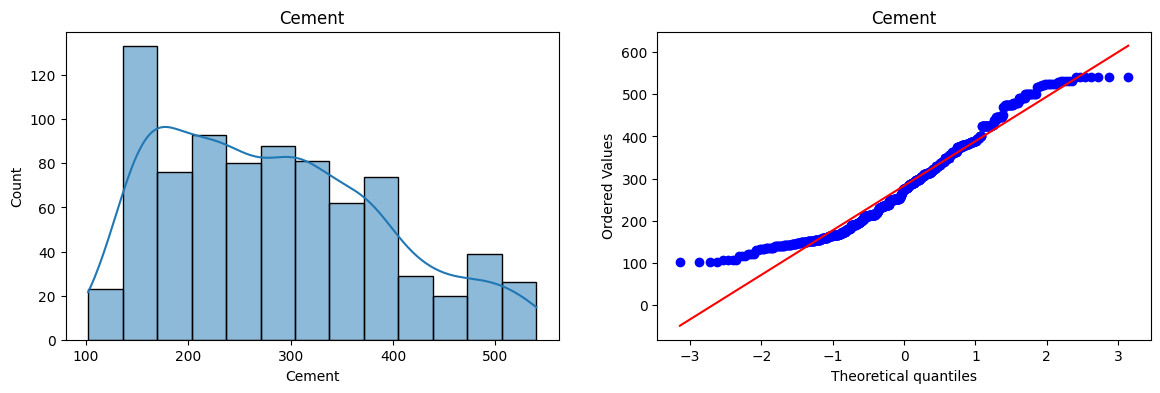

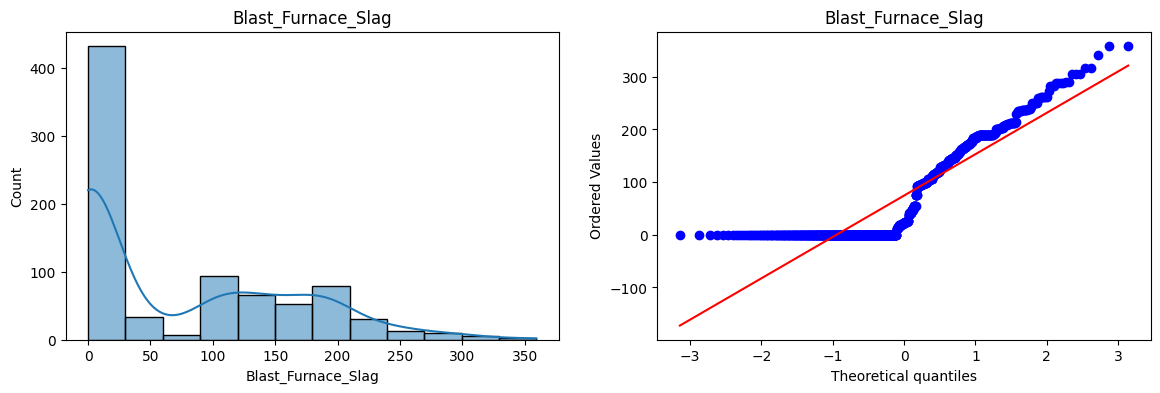

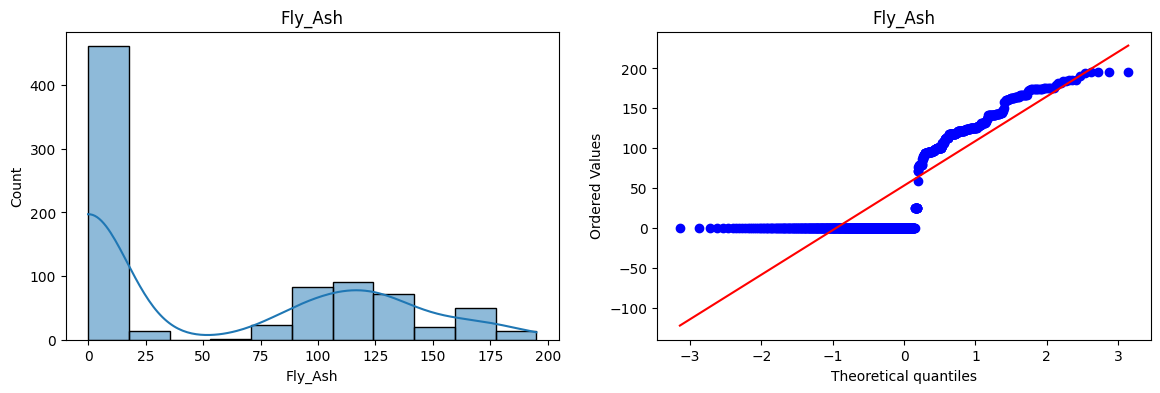

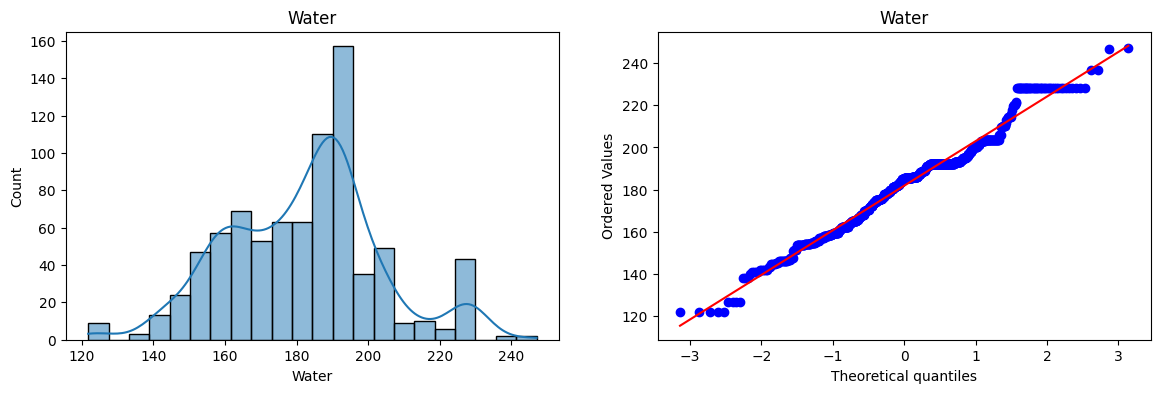

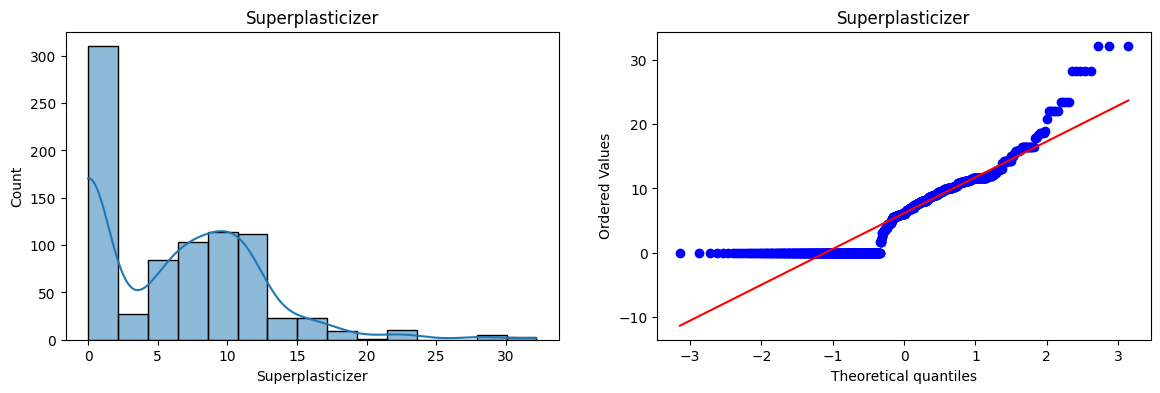

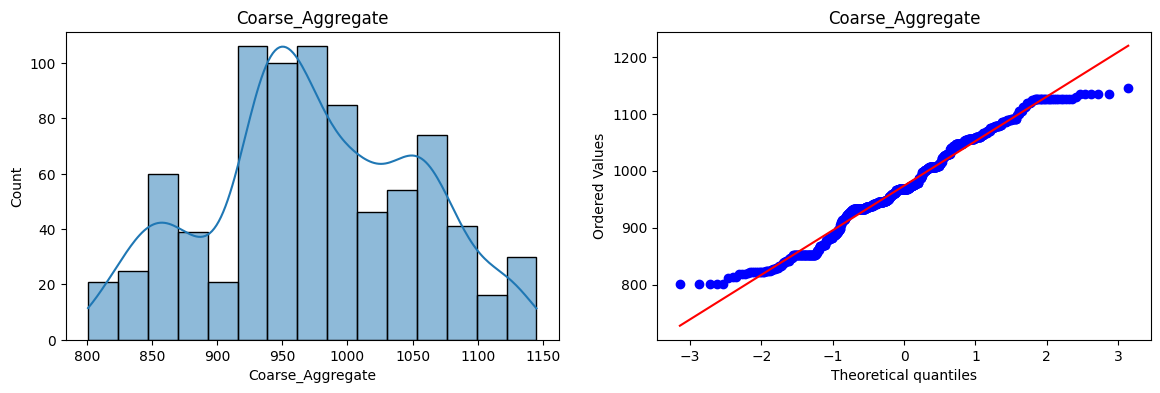

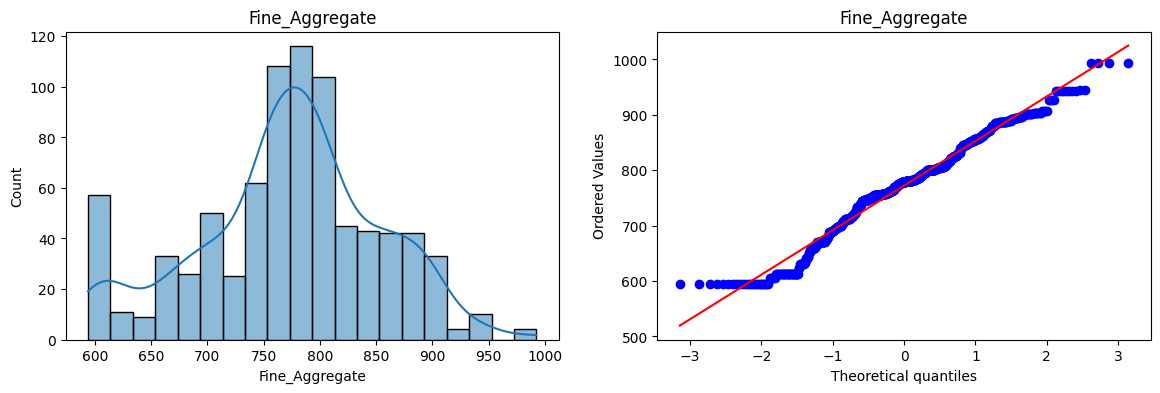

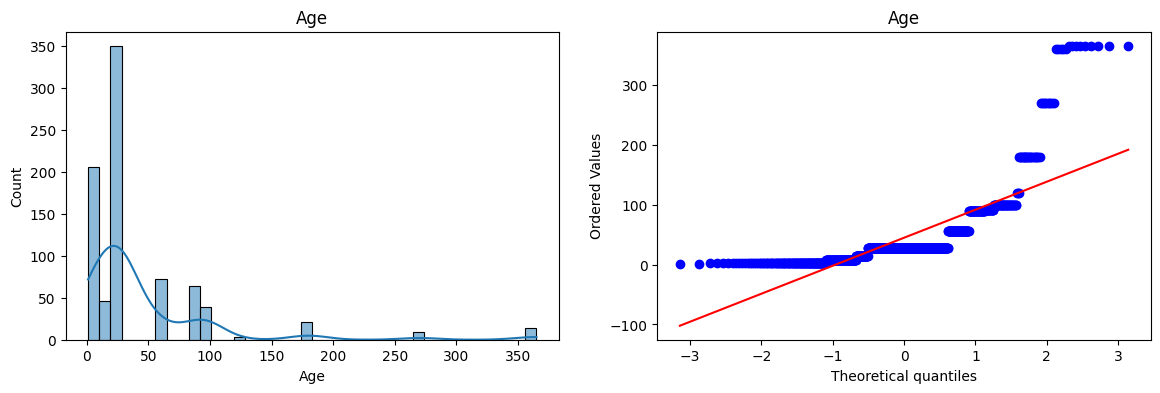

In [20]:
# flotting the displots with any transformation. all column have how to distribution
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

for col in x_train.columns:
    plt.figure(figsize=(14,4))

    plt.subplot(121)
    sns.histplot(x_train[col], kde=True)
    plt.title(col)

    plt.subplot(122)
    stats.probplot(x_train[col], dist='norm', plot=plt)
    plt.title(col)

    plt.show()

# applying box-cox transform

In [21]:
# applying box-cox transform
pt=PowerTransformer(method='box-cox')

x_train_transformed=pt.fit_transform(x_train+0.000001)
x_test_transformed=pt.fit_transform(x_test+0.000001)

pd.DataFrame({'cols':x_train.columns,'box_cox_lambda':pt.lambdas_})

# it will give the lambda values for each and every columns likr(Cement =0.21560)

,cols,box_cox_lambda
0,Cement,0.215602
1,Blast_Furnace_Slag,0.025996
2,Fly_Ash,-0.006544
3,Water,0.959062
4,Superplasticizer,0.103365
5,Coarse_Aggregate,1.192492
6,Fine_Aggregate,1.973781
7,Age,-0.014692


In [22]:
# after transform
lr=LinearRegression()
lr.fit(x_train_transformed,y_train)

y_pred2=lr.predict(x_test_transformed)

r2_score(y_test,y_pred2)

0.8055321002541034

In [23]:
# using cross val score after tranform

pt=PowerTransformer(method='box-cox')
x_transformed =pt.fit_transform(x+0.000001)

lr=LinearRegression()
np.mean(cross_val_score(lr,x_transformed,y,scoring='r2'))

np.float64(0.6662950327179041)

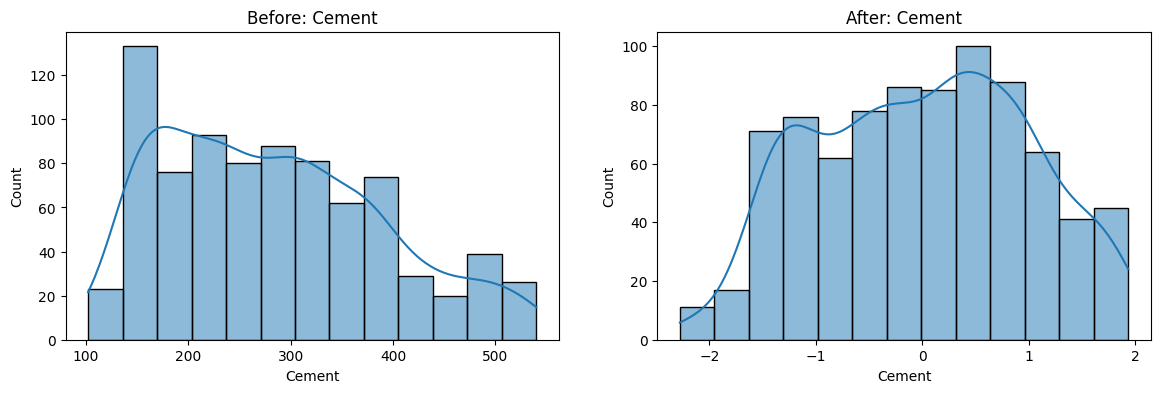

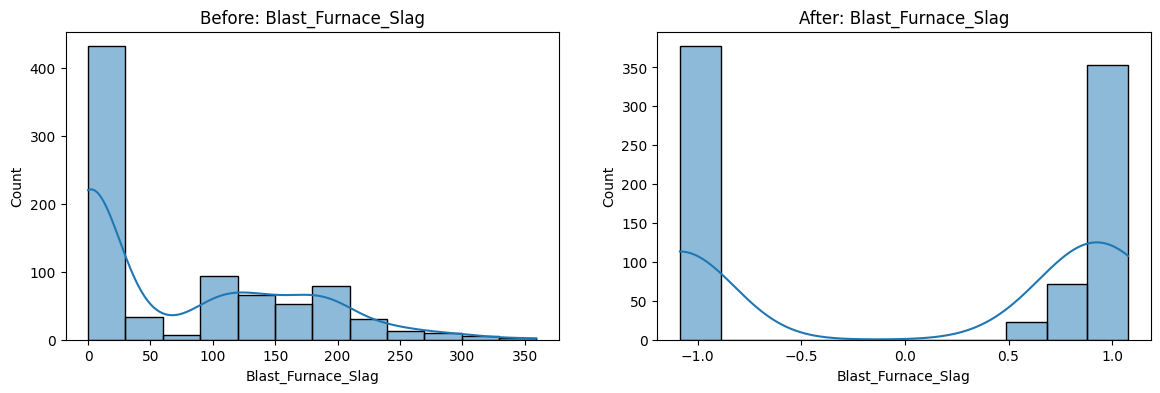

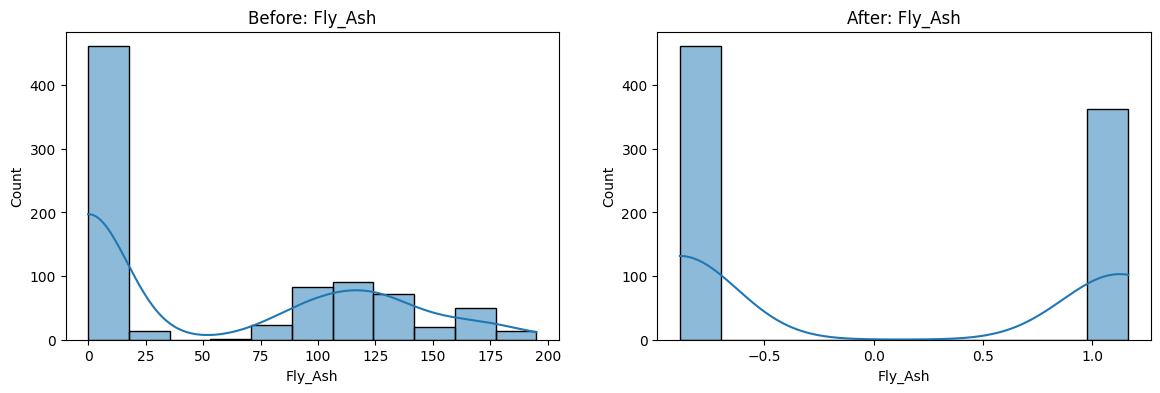

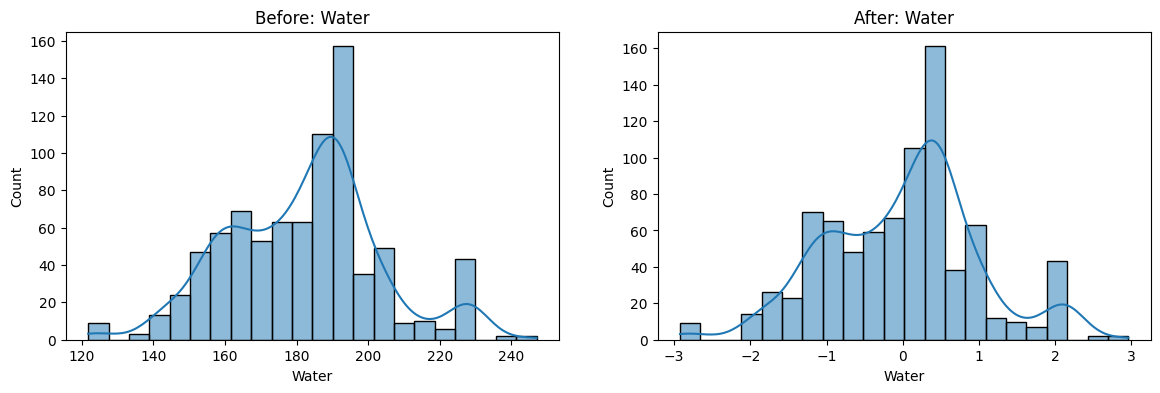

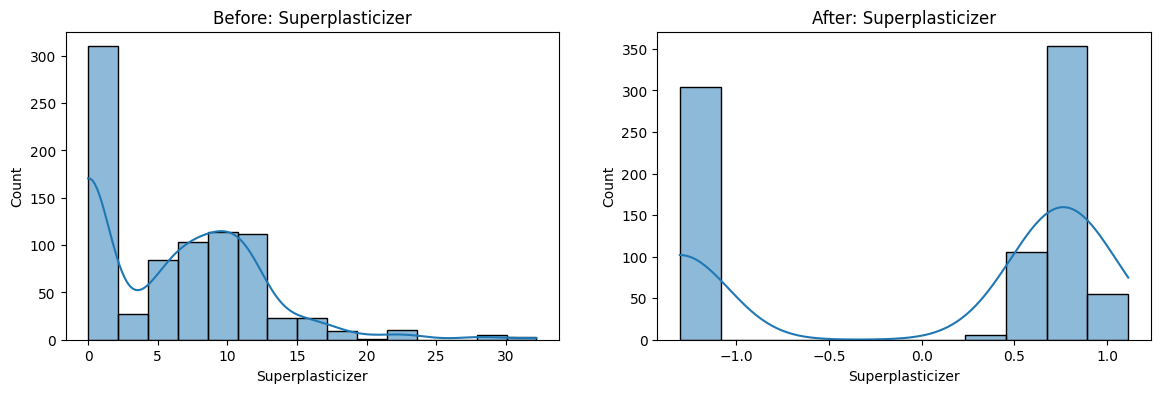

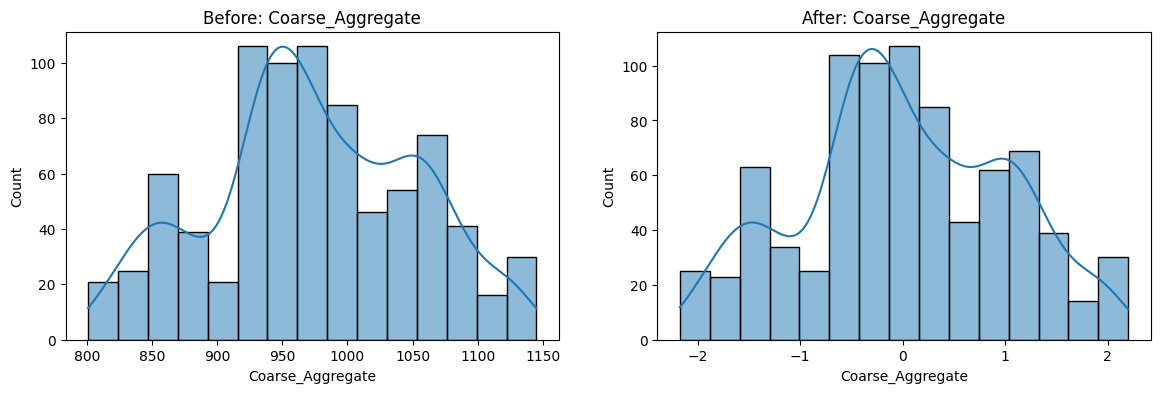

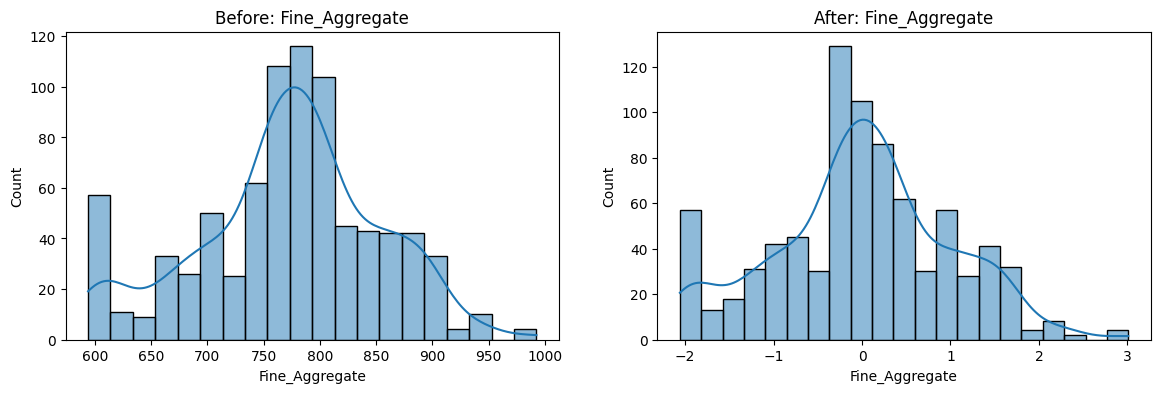

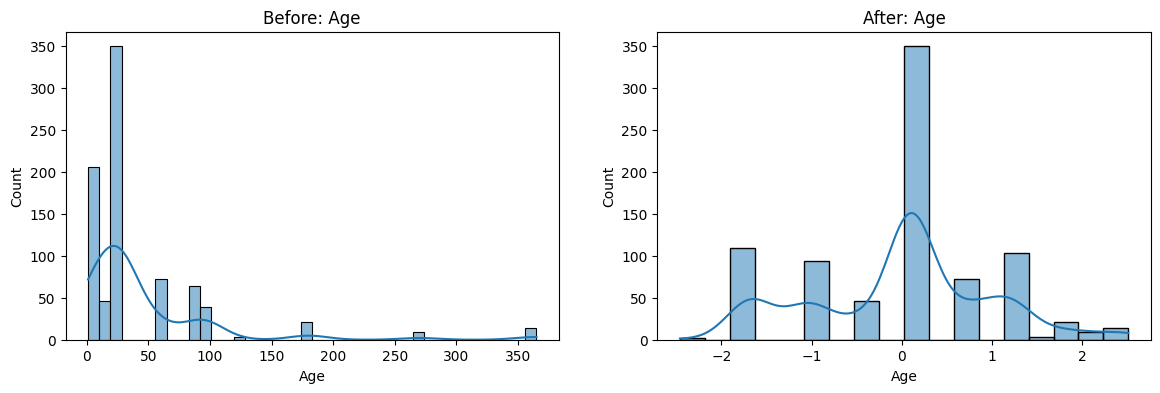

In [24]:
# before and after comparision for box-cox-plot
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

x_train_transformed = pd.DataFrame(
    x_train_transformed,
    columns=x_train.columns
)

for col in x_train_transformed.columns:
    plt.figure(figsize=(14,4))

    # Original data
    plt.subplot(121)
    sns.histplot(x_train[col], kde=True)
    plt.title("Before: " + col)

    # Transformed data
    plt.subplot(122)
    sns.histplot(x_train_transformed[col], kde=True)
    plt.title("After: " + col)

    plt.show()

# applying yeo-johnson transform

In [25]:
pt2=PowerTransformer()
x_train_transformed2=pt2.fit_transform(x_train)
x_test_transformed2=pt2.fit_transform(x_test)

lr=LinearRegression()
lr.fit(x_train_transformed2,y_train)

y_pred3=lr.predict(x_test_transformed2)

print(r2_score(y_test,y_pred3))

pd.DataFrame({'cols':x_train.columns,'yeo_johnson_lambda':pt2.lambdas_})

0.8153845514645103


,cols,yeo_johnson_lambda
0,Cement,0.213025
1,Blast_Furnace_Slag,0.020476
2,Fly_Ash,-0.038218
3,Water,0.958936
4,Superplasticizer,0.304951
5,Coarse_Aggregate,1.192751
6,Fine_Aggregate,1.975085
7,Age,-0.062443


In [26]:
# using cross val score after tranform

pt=PowerTransformer()
x_transformed =pt.fit_transform(x)

lr=LinearRegression()
np.mean(cross_val_score(lr,x_transformed,y,scoring='r2'))

np.float64(0.6834625126992433)

In [27]:
x_train_transformed2=pd.DataFrame(x_train_transformed2,columns=x_train.columns)

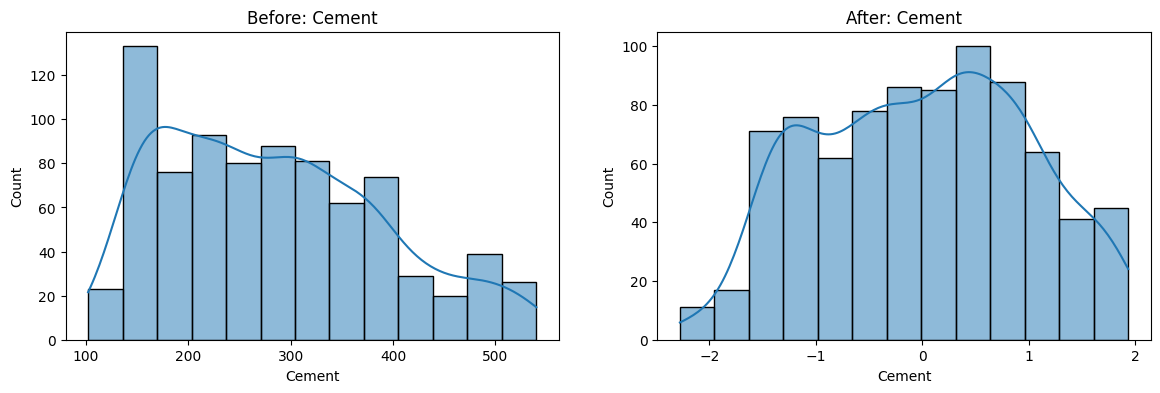

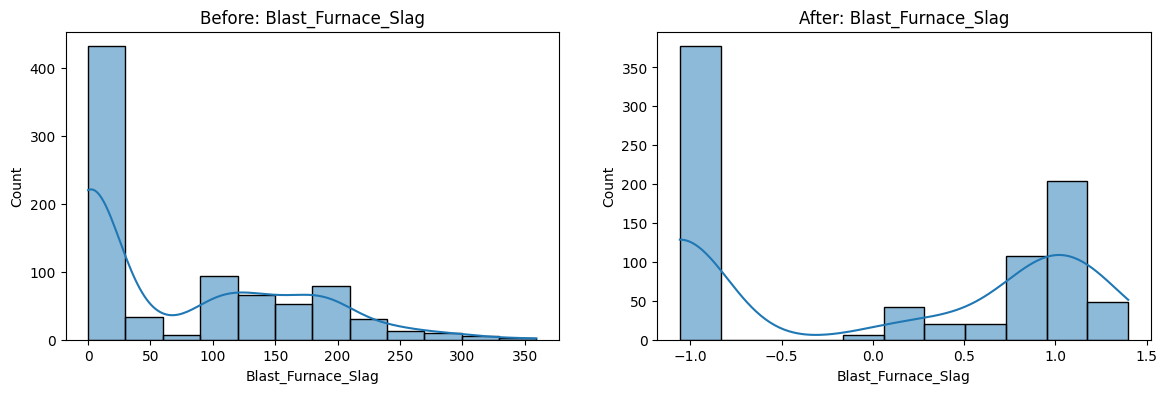

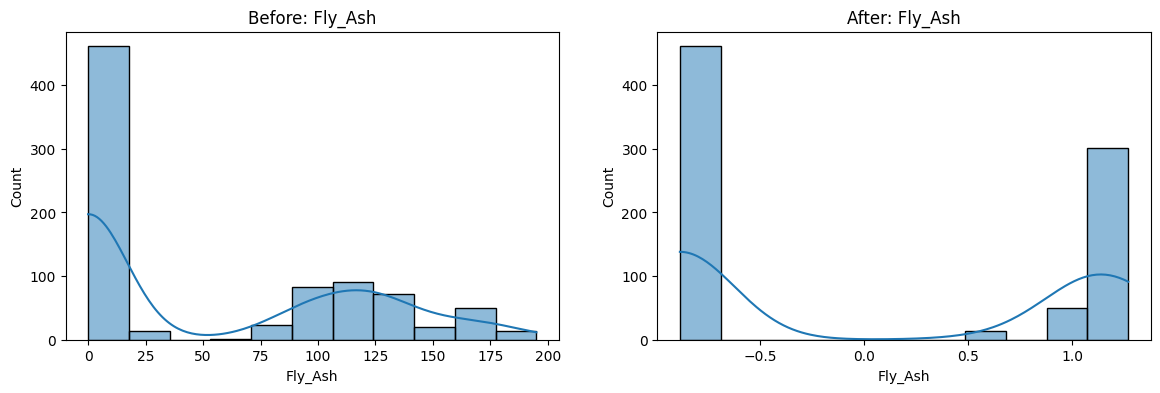

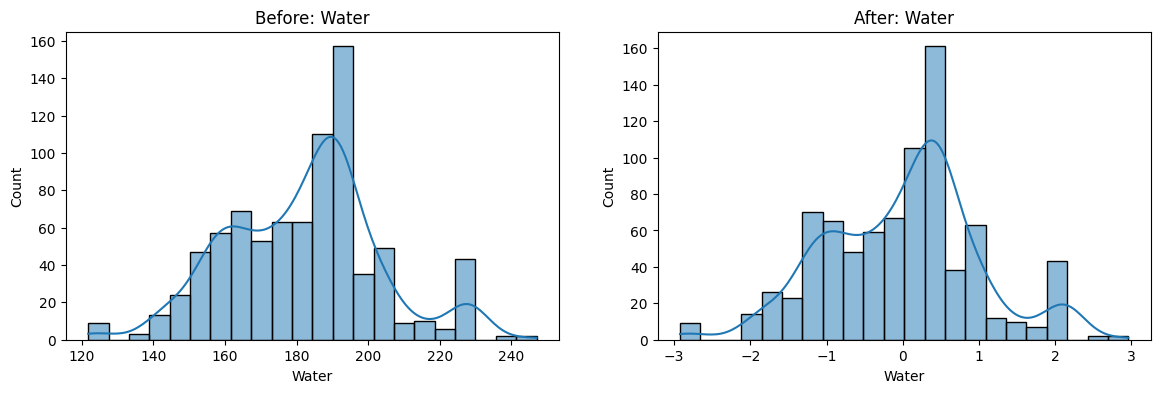

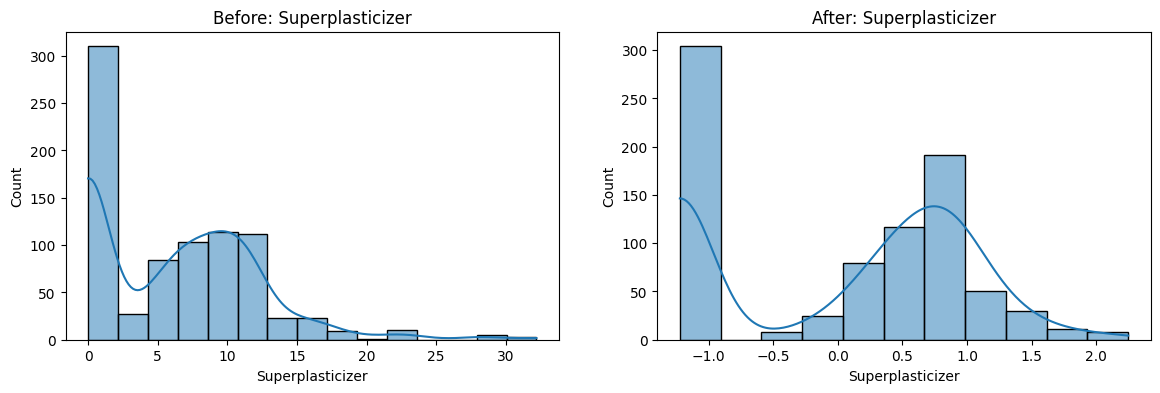

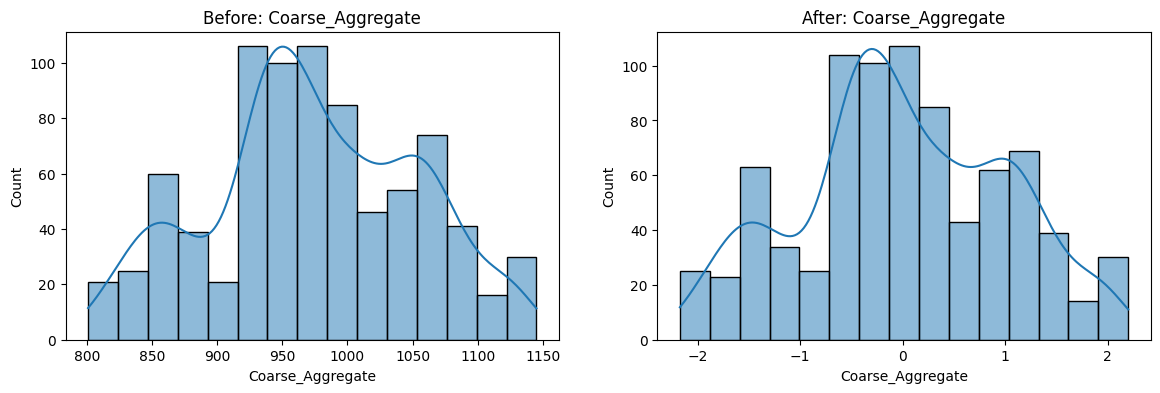

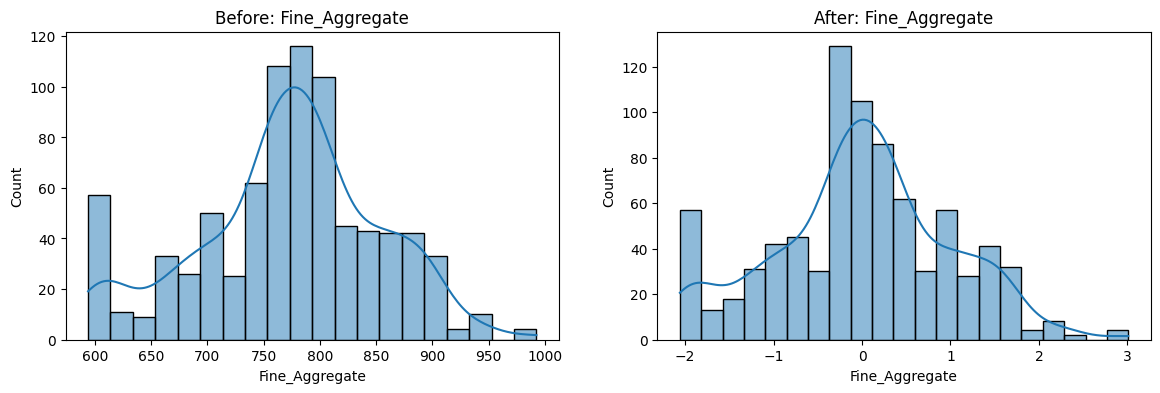

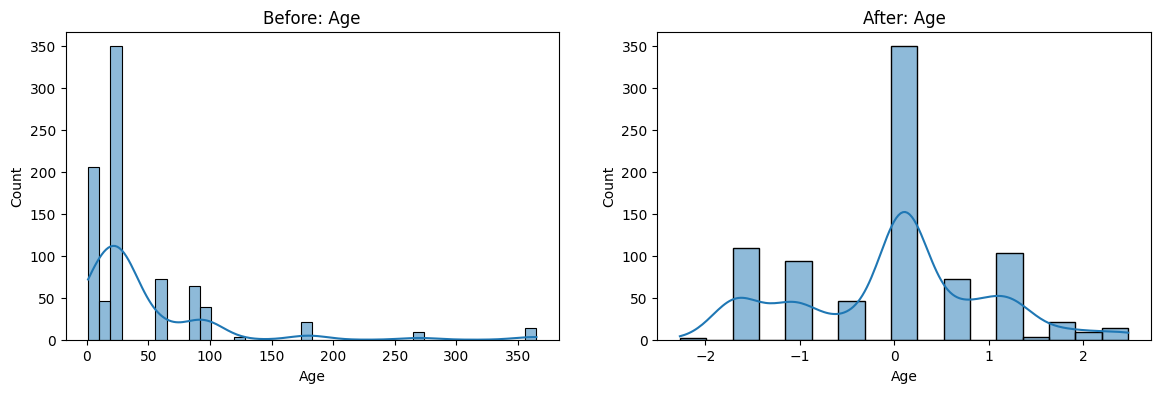

In [28]:
# before and after comparision for yeo-johnson

import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

x_train_transformed = pd.DataFrame(
    x_train_transformed2,
    columns=x_train.columns
)

for col in x_train_transformed2.columns:
    plt.figure(figsize=(14,4))

    # Original data
    plt.subplot(121)
    sns.histplot(x_train[col], kde=True)
    plt.title("Before: " + col)

    # Transformed data
    plt.subplot(122)
    sns.histplot(x_train_transformed2[col], kde=True)
    plt.title("After: " + col)

    plt.show()

In [29]:
# side by side lambdas
pd.DataFrame({'cols': x_train.columns,'box_cox_lambdas':pt.lambdas_,'yeo_johnson_lambdas':pt2.lambdas_})

,cols,box_cox_lambdas,yeo_johnson_lambdas
0,Cement,0.169544,0.213025
1,Blast_Furnace_Slag,0.016633,0.020476
2,Fly_Ash,-0.136480,-0.038218
3,Water,0.808438,0.958936
4,Superplasticizer,0.264160,0.304951
5,Coarse_Aggregate,1.129395,1.192751
6,Fine_Aggregate,1.830764,1.975085
7,Age,0.001771,-0.062443
